# 02 — GPS Deep Dive (single-day sample, 2025-03-18)

**Goal:** characterise the GPS data — vehicle activity, speed profiles, dwell behaviour, route
coverage — to validate which GPS-driven features are feasible.

**Caveat:** local sample is *one day*. The 50-day full set must be downloaded from Kaggle for any
temporal-pattern feature. This notebook documents what the data *looks like* so we know what
features get unlocked when the full set arrives.


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from src.duckdb_loader import BusDuckDB

sns.set_theme(style='whitegrid', context='notebook')
db = BusDuckDB('../data', ':memory:')
db.register_views()
print('OK')


INFO | DuckDB ready


INFO | View 'tickets' registered (90 file(s))


INFO | View 'payments' registered (90 file(s))


INFO | View 'gps_raw' registered


INFO | View 'gps_trips' registered


INFO | View 'gps_stop_times' registered


... (16 outputs left out)

INFO | View 'ticket_schools' registered


INFO | View 'stops' registered


INFO | View 'mapping' registered


OK


## 1. Vehicle activity timeline

How many vehicles are *actively pinging* across the day? This shows the operating envelope.


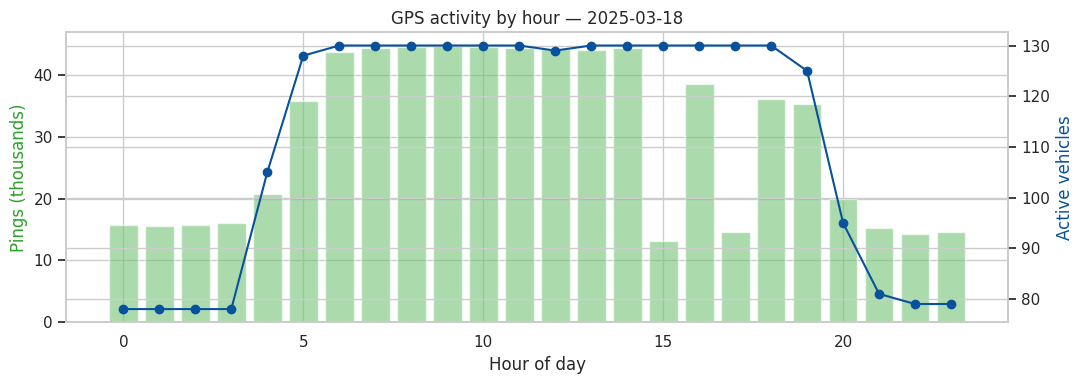

Peak active vehicles in any hour: 130
Total unique vehicles seen: 131


In [2]:
active = db.query('''
    SELECT EXTRACT(hour FROM datetime) AS hour,
           COUNT(DISTINCT vehicle) AS active_vehicles,
           COUNT(*) AS pings
    FROM gps_raw
    GROUP BY hour ORDER BY hour
''').to_pandas()

fig, ax1 = plt.subplots(figsize=(11,4))
ax1.bar(active['hour'], active['pings']/1000, color='#74c476', alpha=0.6, label='Pings (k)')
ax1.set_ylabel('Pings (thousands)', color='#2ca02c')
ax1.set_xlabel('Hour of day')
ax2 = ax1.twinx()
ax2.plot(active['hour'], active['active_vehicles'], 'o-', color='#08519c', label='Active vehicles')
ax2.set_ylabel('Active vehicles', color='#08519c')
plt.title('GPS activity by hour — 2025-03-18')
plt.tight_layout(); plt.show()
print(f'Peak active vehicles in any hour: {active["active_vehicles"].max()}')
print(f'Total unique vehicles seen: ' + str(db.query("SELECT COUNT(DISTINCT vehicle) AS n FROM gps_raw").to_pandas()['n'][0]))


## 2. Speed distribution — operating regime fingerprint

A bimodal distribution with a spike near 0 km/h (stops) and a wider hump (cruising)
is the *expected* signature of a city bus. Deviations flag data-quality issues.


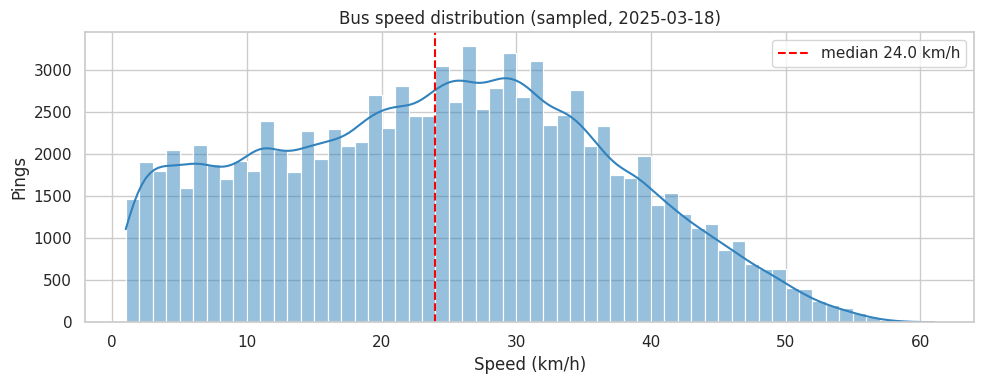

count    100590.00
mean         23.91
std          12.68
min           1.00
25%          14.00
50%          24.00
75%          33.00
max          61.00
Name: speed, dtype: float64


In [3]:
speeds = db.query('''
    SELECT speed FROM gps_raw
    WHERE speed IS NOT NULL AND speed >= 0 AND speed <= 100
    USING SAMPLE 200000 ROWS (reservoir)
''').to_pandas()

fig, ax = plt.subplots(figsize=(10,4))
sns.histplot(speeds['speed'], bins=60, kde=True, ax=ax, color='#3182bd')
ax.axvline(speeds['speed'].median(), ls='--', color='red', label=f'median {speeds["speed"].median():.1f} km/h')
ax.set_xlabel('Speed (km/h)'); ax.set_ylabel('Pings')
ax.set_title('Bus speed distribution (sampled, 2025-03-18)')
ax.legend(); plt.tight_layout(); plt.show()

print(speeds['speed'].describe().round(2))


## 3. Stopped-vs-moving split

If we threshold *speed ≤ 1 km/h* as "stopped", how much of fleet-time is spent stationary?
This is the upper bound for dwell/idle analytics.


In [4]:
r = db.query('''
    SELECT
      SUM(CASE WHEN speed <= 1 THEN 1 ELSE 0 END)::DOUBLE / COUNT(*) AS stopped_pct,
      AVG(speed) AS avg_speed,
      MEDIAN(speed) AS median_speed
    FROM gps_raw WHERE speed IS NOT NULL
''').to_pandas().iloc[0]
print(f'Stopped (≤1 km/h):  {100*r["stopped_pct"]:.1f}% of all pings')
print(f'Average speed (all pings, incl. idle): {r["avg_speed"]:.1f} km/h')
print(f'Median speed: {r["median_speed"]:.1f} km/h')


Stopped (≤1 km/h):  1.5% of all pings
Average speed (all pings, incl. idle): 23.9 km/h
Median speed: 24.0 km/h


## 4. Door events — boarding moments

`door_up` / `door_down` flags fire when doors open/close. Frequency per vehicle is a rough
proxy for stops served. Combined with AFC boardings, this could quantify "door-time per
boarding" — an efficiency metric.


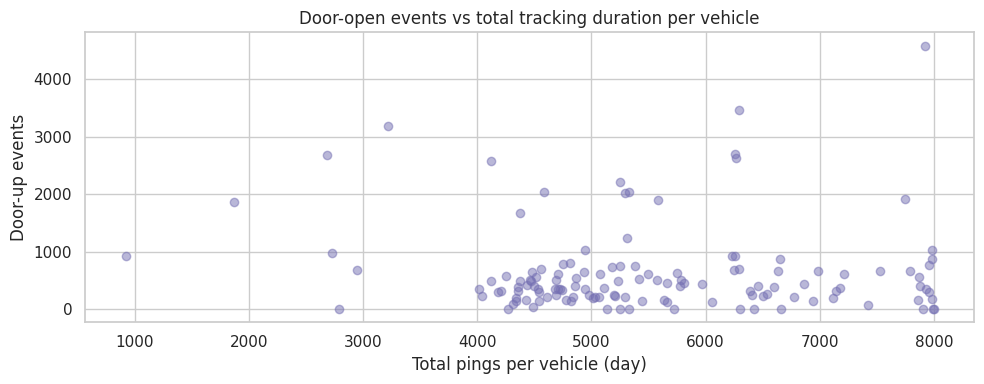

    vehicle door_up_events door_down_events  pings
0  50H41908           4589             4589   7925
1  50H41225           3470             3470   6294
2  50H40865           3192             3192   3216
3  50H40954           2693             2693   6261
4  50H41459           2680             2680   2680
5  50H40300           2639             2639   6266
6  50H40056           2585             2585   4120
7  50H40588           2211             2211   5254


In [5]:
door = db.query('''
    SELECT vehicle,
           SUM(CASE WHEN door_up THEN 1 ELSE 0 END) AS door_up_events,
           SUM(CASE WHEN door_down THEN 1 ELSE 0 END) AS door_down_events,
           COUNT(*) AS pings
    FROM gps_raw
    GROUP BY vehicle
    HAVING pings > 100
    ORDER BY door_up_events DESC
''').to_pandas()

fig, ax = plt.subplots(figsize=(10,4))
ax.scatter(door['pings'], door['door_up_events'], alpha=0.5, color='#7570b3')
ax.set_xlabel('Total pings per vehicle (day)')
ax.set_ylabel('Door-up events')
ax.set_title('Door-open events vs total tracking duration per vehicle')
plt.tight_layout(); plt.show()
print(door.head(8))


## 5. Spatial coverage — where do the buses actually go?

A density map of GPS pings gives us a visual sanity check: do they trace the bus network?
Concentrations should align with central HCMC corridors.


In [6]:
coords = db.query('''
    SELECT lat, lng FROM gps_raw
    WHERE lat BETWEEN 10.5 AND 11.0 AND lng BETWEEN 106.4 AND 107.0
    USING SAMPLE 50000 ROWS (reservoir)
''').to_pandas()

fig = px.density_mapbox(
    coords, lat='lat', lon='lng', radius=4,
    center=dict(lat=10.78, lon=106.69), zoom=10.5,
    mapbox_style='carto-positron',
    title=f'GPS ping density on 2025-03-18 (sample of {len(coords):,} points)',
)
fig.update_layout(height=600, margin=dict(l=0,r=0,t=40,b=0))
fig.show()


/tmp/ipykernel_26205/2671860860.py:7: DeprecationWarning: *density_mapbox* is deprecated! Use *density_map* instead. Learn more at: https://plotly.com/python/mapbox-to-maplibre/
  fig = px.density_mapbox(


## 6. Extracted trip timeline — per route

For the 9 routes processed into `gps_extracted`, trip start times tell us the headway/frequency
profile of the day.


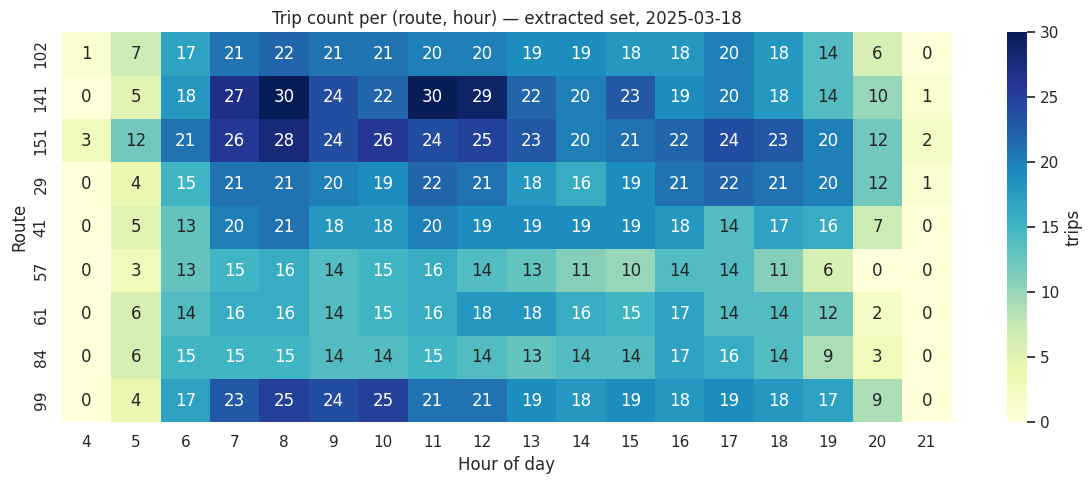

In [7]:
# Trip departures per route per hour
trips = db.query('''
    SELECT route_no,
           CAST(time_in_seconds / 3600 AS INTEGER) AS hour,
           COUNT(DISTINCT trip_id) AS trips
    FROM gps_extracted
    GROUP BY route_no, hour
    ORDER BY route_no, hour
''').to_pandas()

pivot = trips.pivot(index='route_no', columns='hour', values='trips').fillna(0)
fig, ax = plt.subplots(figsize=(12,5))
sns.heatmap(pivot, cmap='YlGnBu', annot=True, fmt='.0f', cbar_kws=dict(label='trips'), ax=ax)
ax.set_title('Trip count per (route, hour) — extracted set, 2025-03-18')
ax.set_xlabel('Hour of day'); ax.set_ylabel('Route')
plt.tight_layout(); plt.show()


## 7. Dwell times — distribution per route

From `gps_stop_times`, dwell_time at each stop tells us how long the bus held the platform.
High dwell with high boardings = efficient. High dwell with low boardings = wasted time.


INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


/tmp/ipykernel_26205/1617661451.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


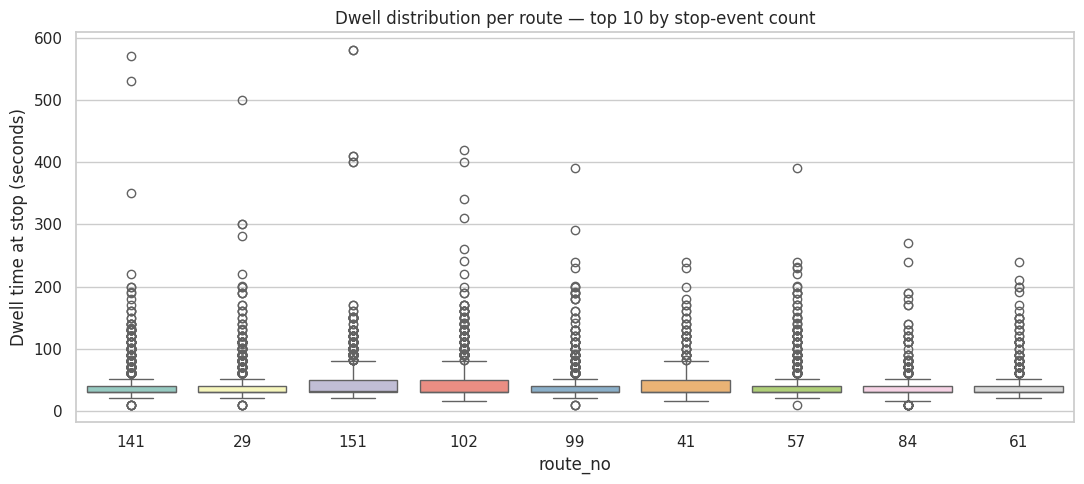

          count  median       mean
route_no                          
141        2335    30.0  38.937473
29         1998    30.0  38.911912
151        1922    31.0  47.252862
102        1636    30.0  45.446822
99         1591    30.0  40.135764
41         1218    30.0  41.715928
57         1061    30.0  43.505184
84          846    30.0  39.840426
61          699    30.0  40.696710


In [8]:
dwell = db.query('''
    SELECT t.route_id, gr.route_no, st.dwell_time
    FROM gps_stop_times st
    JOIN gps_trips t   USING (trip_id)
    JOIN gps_routes gr USING (route_id)
    WHERE st.dwell_time > 0 AND st.dwell_time < 600
''').to_pandas()

fig, ax = plt.subplots(figsize=(11,5))
top_routes = dwell['route_no'].value_counts().head(10).index
sns.boxplot(
    data=dwell[dwell['route_no'].isin(top_routes)],
    x='route_no', y='dwell_time', ax=ax, palette='Set3',
    order=top_routes,
)
ax.set_ylabel('Dwell time at stop (seconds)')
ax.set_title('Dwell distribution per route — top 10 by stop-event count')
plt.tight_layout(); plt.show()
print(dwell.groupby('route_no')['dwell_time'].agg(['count','median','mean']).sort_values('count', ascending=False).head(10))


## Takeaways — GPS feasibility

| Feature | Status with 1-day sample | Unlocks with full 50 days |
|---|---|---|
| Spatial coverage map | ✅ usable as snapshot | 🚀 multi-day density, traffic-sensor mode |
| Speed regime / fleet snapshot | ✅ | 🚀 traffic congestion heatmap by hour-of-week |
| Headway/frequency profile | ⚠️ 1 day only | 🚀 reliability/CoV per route |
| Driver fingerprint | ❌ needs multi-day | ✅ |
| Arrival-time prediction with bands | ❌ needs temporal variation | ✅ |
| Dwell vs boardings join (with AFC) | ⚠️ aggregate only | ✅ aggregate (no trip-level join across years) |
| April 30 parade case study | ❌ need late-April data | ✅ |

**Bottom line:** the 1-day GPS unlocks operational snapshot dashboards (today's coverage,
hourly activity, speed/dwell profiles). Time-series and ML features must wait on the full
download — but the *processing pipeline* can be developed and validated against this 1-day
sample now.
